# Hedging bot: delta hedging a book of APOs

The book in `portfolios/example_book.yaml` holds three APOs with illustrative terms:

| id | trade | pricing month | position |
|---|---|---|---|
| APO-001 | Brent put, strike 72 | Jan 2027 | bought 20 000 bbl |
| APO-002 | WTI - Brent put, strike -4 | Apr 2027 | sold 15 000 bbl |
| APO-003 | HO - Brent crack call, strike 32 | Jun 2027 | sold 25 000 bbl |

Every business day the bot prices the book, nets the deltas per underlying (Brent is in all
three trades) and holds the opposite in futures. The market is simulated, so the same book can
be replayed on many paths with the volatility we choose.

1. One simulated path: prices, hedge position
2. P&L: options alone vs hedged book
3. P&L explain
4. Implied vs realised vol, on the crack alone
5. Hedge frequency, model and lot rounding

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import QuantLib as ql

from cmdty import MarketData, Portfolio, Pricer, Quote, load_portfolio
from cmdty.hedging import HedgeSettings, HedgingBot, book_risk
from cmdty.market import SimulatedSource, any_exchange_calendar
from cmdty.plotting import MUTED, SERIES, TEXT, area_line, last_value, price_axis_right, ref_line, titles, use_style

use_style()
# deep in the money late in the month Kirk hands over to Bachelier, already tested
import warnings
warnings.filterwarnings("ignore", message="Kirk undefined")

## 1. One simulated path

Starting market on 10 Nov 2026: forwards and implied vols per underlying, correlations between
them. The source moves the three futures on every day either exchange settles, here with
realised vols equal to the implied ones.

In [15]:
book = load_portfolio("../portfolios/example_book.yaml")

start = MarketData(
    today=ql.Date(10, 11, 2026), 
    rate=0.04,
    quotes={"HO": Quote(105.0, 0.30), "BRENT": Quote(75.0, 0.32), "WTI": Quote(71.0, 0.33)},
    correlations={("HO", "BRENT"): 0.95, ("WTI", "BRENT"): 0.97, ("HO", "WTI"): 0.93},
)
calendar = any_exchange_calendar(["NYMEX", "ICE-EU"])

# horizon
end = ql.Date(15, 7, 2027)

pricer = Pricer(market=start)
pd.DataFrame({
    t.id: {"PV $": t.instrument.quantity * pricer.pv(t.instrument),
           **{f"delta {u} bbl": t.instrument.quantity * d
              for u, d in pricer.deltas(t.instrument).items()}}
    for t in book
}).T.fillna(0).round(0)

,PV $,delta BRENT bbl,delta WTI bbl,delta HO bbl
APO-001,51013.0,-7019.0,0.0,0.0
APO-002,-22536.0,-7644.0,7341.0,0.0
APO-003,-65367.0,10009.0,0.0,-10443.0


In [16]:
risk = book_risk(book, pricer)
print("net deltas, bbl:", {u: round(d) for u, d in risk.deltas.items()})

net deltas, bbl: {'BRENT': -4653, 'WTI': 7341, 'HO': -10443}


Brent shows up in all three trades with deltas of different signs, so most of it cancels: the
bot only hedges what is left. That is the point of hedging at book level.

In [18]:
df.columns

Index(['option_pv', 'option_pnl', 'hedge_pnl', 'cost', 'pnl', 'F_HO',
       'delta_HO', 'lots_HO', 'F_BRENT', 'delta_BRENT', 'lots_BRENT', 'F_WTI',
       'delta_WTI', 'lots_WTI', 'explain_delta', 'explain_gamma',
       'explain_theta', 'explain_vega', 'explain_cash', 'explain_unexplained',
       'cum_pnl'],
      dtype='object')

               option_pv  option_pnl  hedge_pnl   cost    pnl   F_HO  \
date                                                                   
2026-11-10 -36889.780751         0.0        0.0  110.0 -110.0  105.0   

                delta_HO  lots_HO  F_BRENT  delta_BRENT  ...  F_WTI  \
date                                                     ...          
2026-11-10 -10443.291589       10     75.0 -4653.487915  ...   71.0   

              delta_WTI  lots_WTI  explain_delta  explain_gamma  \
date                                                              
2026-11-10  7341.297287        -7            NaN            NaN   

            explain_theta  explain_vega  explain_cash  explain_unexplained  \
date                                                                         
2026-11-10            NaN           NaN           NaN                  NaN   

            cum_pnl  
date                 
2026-11-10   -110.0  

[1 rows x 21 columns]


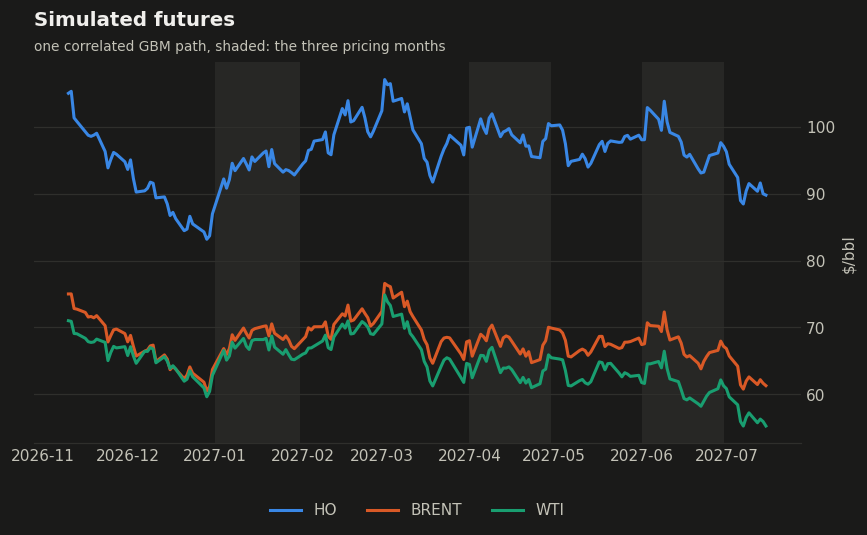

In [17]:
source = SimulatedSource(start, end, calendar, seed=2)
run = HedgingBot(book, source, HedgeSettings(cost_per_lot=5)).run()
df = run.to_frame()
print(df.head(1))
df.index = pd.to_datetime(df.index)
months = {"Jan": ("2027-01-01", "2027-01-31"), "Apr": ("2027-04-01", "2027-04-30"),
          "Jun": ("2027-06-01", "2027-06-30")}

def shade(ax):
    for a, b in months.values():
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=MUTED, alpha=0.08, linewidth=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
for u, color in zip(("HO", "BRENT", "WTI"), SERIES):
    ax.plot(df.index, df[f"F_{u}"], color=color, label=u)
shade(ax)
price_axis_right(ax)
ax.set(ylabel="$/bbl")
titles(ax, "Simulated futures", "one correlated GBM path, shaded: the three pricing months")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.show()

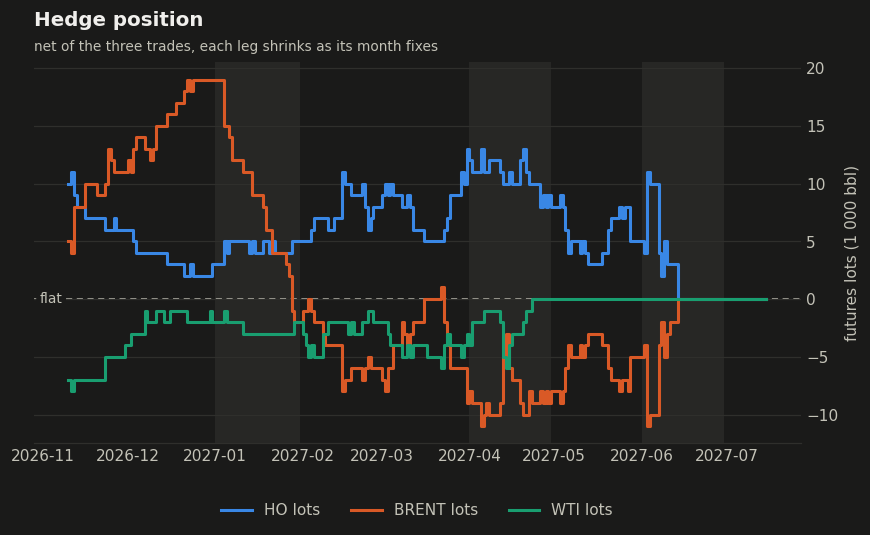

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for u, color in zip(("HO", "BRENT", "WTI"), SERIES):
    ax.step(df.index, df[f"lots_{u}"], where="post", color=color, label=f"{u} lots")
shade(ax)
ref_line(ax, 0, "flat")
price_axis_right(ax)
ax.set(ylabel="futures lots (1 000 bbl)")
titles(ax, "Hedge position", "net of the three trades, each leg shrinks as its month fixes")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.show()

Each trade's deltas fade during its own pricing month, as fixings lock the average: the Brent
put in January, the WTI - Brent spread in April, the crack in June. The futures follow, and
after the last payment nothing is left.

## 2. P&L: options alone vs hedged book

Day 0 is at fair value, so the P&L starts at 0. Option P&L is the change in PV plus the payoffs
when they are paid. Hedge P&L is the variation margin on the futures held overnight.

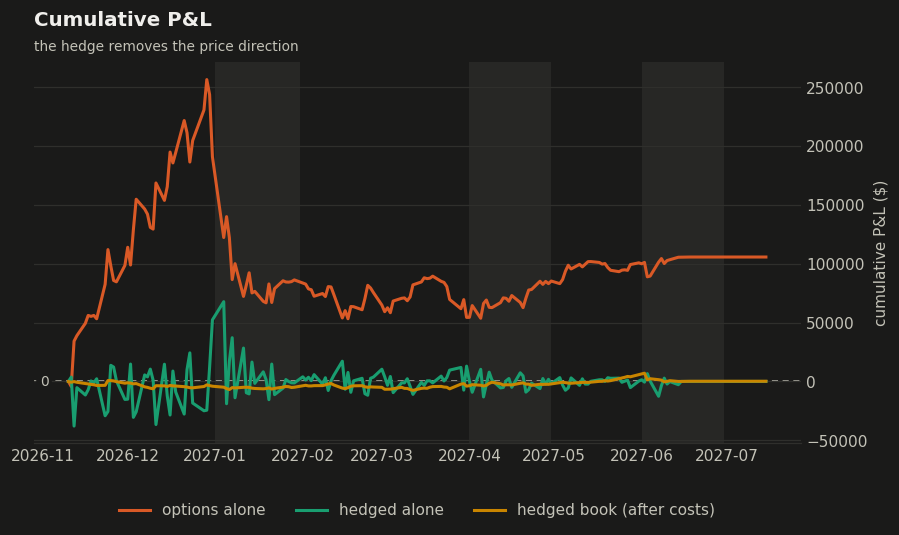

options alone: +105,743 $
hedged book  : +191 $   (costs 1,930 $)


In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df.index, df["option_pnl"].cumsum(), color=SERIES[1], label="options alone")
ax.plot(df.index, df["hedge_pnl"], color=SERIES[2], label="hedged alone")
ax.plot(df.index, df["cum_pnl"], color=SERIES[3], label="hedged book (after costs)")
ref_line(ax, 0, "0")
shade(ax)
price_axis_right(ax)
ax.set(ylabel="cumulative P&L ($)")
titles(ax, "Cumulative P&L", "the hedge removes the price direction")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.show()
print(f"options alone: {df['option_pnl'].sum():+,.0f} $")
print(f"hedged book  : {run.total_pnl:+,.0f} $   (costs {df['cost'].sum():,.0f} $)")

## 3. P&L explain

Every day the option P&L is split with yesterday's greeks:

dV ≈ Δ dF + ½ Γ dF² + Θ dt + ν dσ (+ payoffs paid)

Γ includes the cross terms between underlyings, which matter for spreads. The delta of the
options and the futures P&L almost cancel. What remains is mostly **gamma against theta**:
the book is net short options, it collects theta and pays gamma when the market moves.

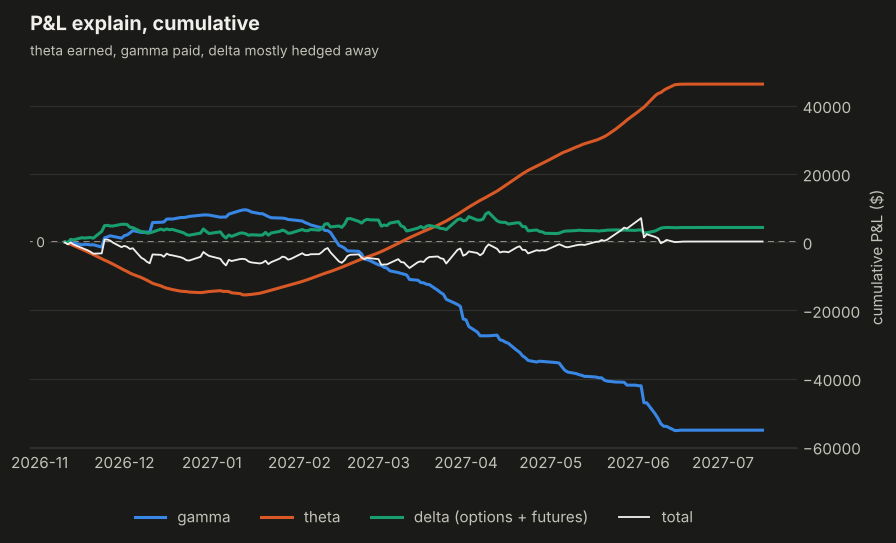

,total $
delta (options + futures),4301.0
gamma,-55087.0
theta,46313.0
vega,0.0
costs,-1930.0
unexplained,6593.0
= hedged P&L,191.0


In [7]:
lines = pd.DataFrame({
    "delta (options + futures)": df["explain_delta"] + df["hedge_pnl"],
    "gamma": df["explain_gamma"],
    "theta": df["explain_theta"],
    "vega": df["explain_vega"],
    "costs": -df["cost"],
    "unexplained": df["explain_unexplained"],
}).fillna(0)
# a payoff paid shows up as -PV in theta and +cash in cash: net them in theta
lines["theta"] += df["explain_cash"].fillna(0)

fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, s), color in zip(lines[["gamma", "theta", "delta (options + futures)"]].items(), SERIES):
    ax.plot(df.index, s.cumsum(), color=color, label=name)
ax.plot(df.index, df["cum_pnl"], color=TEXT, linewidth=1.2, label="total")
ref_line(ax, 0, "0")
price_axis_right(ax)
ax.set(ylabel="cumulative P&L ($)")
titles(ax, "P&L explain, cumulative", "theta earned, gamma paid, delta mostly hedged away")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.show()

totals = lines.sum().to_frame("total $")
totals.loc["= hedged P&L"] = run.total_pnl
totals.round(0)

On this path the book collects about 46 k$ of theta and pays about 55 k$ of gamma: the
market moved a bit more than the implied vols priced. Unexplained is around a tenth of gamma. It
builds up when an option is at the money near the end of its month, where gamma itself moves a
lot within a day and a second-order expansion is no longer enough. Vega is zero because the
simulated implied vols never move.

## 4. Implied vs realised volatility, on the crack alone

The classic result of delta hedging: a hedged short option earns roughly
½ Γ F² (σ²_implied − σ²_realised) per day. To read it cleanly we take the sold crack call
(APO-003) alone, priced at the implied vols, and let the market realise 60%, 100% and 140% of
them. 40 paths each, costs off.

In [8]:
crack = Portfolio(name="crack", trades=[book.trade("APO-003")])
implied = {u: start.vol(u) for u in start.quotes}
free = HedgeSettings(cost_per_lot=0, explain=False)

def total_pnls(scale, seeds=range(40), settings=free):
    out = []
    for seed in seeds:
        vols = {u: v * scale for u, v in implied.items()}
        src = SimulatedSource(start, end, calendar, realized_vol=vols, seed=seed)
        out.append(HedgingBot(crack, src, settings).run().total_pnl)
    return np.array(out)

scales = [0.6, 1.0, 1.4]
results = {s: total_pnls(s) for s in scales}
pd.DataFrame({f"realised = {s:.0%} of implied": [r.mean(), r.std()]
              for s, r in results.items()}, index=["mean $", "std $"]).round(0)

,realised = 60% of implied,realised = 100% of implied,realised = 140% of implied
mean $,30306.0,214.0,-34540.0
std $,11883.0,9318.0,22487.0


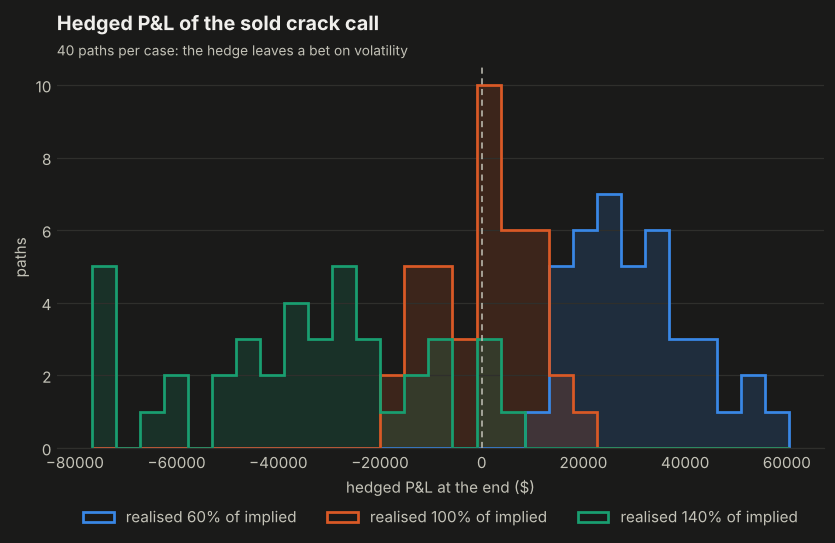

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(min(r.min() for r in results.values()), max(r.max() for r in results.values()), 30)
for (s, r), color in zip(results.items(), SERIES):
    ax.hist(r, bins=bins, color=color, alpha=0.18)
    ax.hist(r, bins=bins, color=color, histtype="step", linewidth=1.8, label=f"realised {s:.0%} of implied")
ax.axvline(0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.set(xlabel="hedged P&L at the end ($)", ylabel="paths")
titles(ax, "Hedged P&L of the sold crack call", "40 paths per case: the hedge leaves a bet on volatility")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.show()

Selling at the implied vol when the market realises less makes money on average, realising
more loses. With realised = implied the mean is close to 0: the premium was fair. The spread of
each histogram is the hedging error from daily rebalancing and lot rounding.

## 5. Hedge frequency, model and lot rounding

Same crack, same 40 paths, realised = implied, costs at 5 $ per lot (0.005 $ per bbl). The last
row hedges in barrels instead of whole lots, to see what the rounding costs.

In [10]:
cases = {
    "Kirk, daily": HedgeSettings(explain=False),
    "Kirk, weekly": HedgeSettings(rebalance_every=5, explain=False),
    "Bachelier, daily": HedgeSettings(model="bachelier", explain=False),
    "Kirk, daily, no lot rounding": HedgeSettings(lot_size=1, cost_per_lot=0.005, explain=False),
}
rows = {}
for name, settings in cases.items():
    runs = [HedgingBot(crack, SimulatedSource(start, end, calendar, seed=s), settings).run()
            for s in range(40)]
    pnl = np.array([r.total_pnl for r in runs])
    costs = np.mean([sum(d.cost for d in r.days) for r in runs])
    rows[name] = {"mean P&L $": pnl.mean(), "std P&L $": pnl.std(), "avg costs $": costs}
pd.DataFrame(rows).T.round(0)

,mean P&L $,std P&L $,avg costs $
"Kirk, daily",-814.0,9452.0,1028.0
"Kirk, weekly",-6187.0,15999.0,585.0
"Bachelier, daily",-5688.0,13948.0,1022.0
"Kirk, daily, no lot rounding",-4146.0,6580.0,1021.0


Reading the table:

- **Weekly hedging** trades about half as much but its P&L is much more spread out.
- **Kirk is the best of the daily hedges.** The simulated market is lognormal, which is what
  Kirk assumes. Bachelier's deltas, built for a normal crack, are off on a 7-month option.
- **Whole lots cost precision**: hedging in barrels cuts the spread by about a third. Rounding
  each leg on its own can also leave outright exposure when the two deltas differ; rounding in
  crack lots first is in the roadmap.

With 40 paths the means carry a standard error of about 1 500 to 2 500 $, so compare the
spreads rather than the means.